In [10]:
%load_ext autoreload
%autoreload 2

In [11]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import os

from matplotlib.patches import Circle

import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from src.bayesian import run_bayesian_roi_model, percentile_normalize
from src.readH5 import get_element_map, threshold_map
from src.feRatio import checkFeRatio, checkFeFWHMRatio, checkFeRatioNew, checkFeRatioWithDy, findFeRatioDyAnomalies
from src.feRatio import checkFeKaFWHMvsDy, checkFeFWHMRatioVsDy, checkFeKaAsymmetryVsDy
from src.elementalRatios import checkElementalRatio, checkDyResidual, checkDyResidualStandardized, create_particle_mask, checkDyResidualStandardizedMasked, selectResidualExtremes

from scipy.ndimage import (
    binary_dilation,
    distance_transform_edt,
    gaussian_filter
)

In [12]:
h5_file = "/Users/Lawrence/Documents/PhD/Projects/REE/Characterization/NSLS2/HXN/xrf/scan2D_324293.h5"
# h5_file = "/Users/Lawrence/Documents/PhD/Projects/REE/Characterization/NSLS2/SRX/scan2D_165161_xs_sum8ch.h5"
# 323932; 323931; 324293; 324289; 324344; 323937

# h5_file = "/Users/Lawrence/Documents/PhD/Projects/REE/Characterization/NSLS2/SRX/autorun_scan2D_165142_xs_sum8ch.h5"

In [13]:
with h5py.File(h5_file, "r") as f:

    counts = f["xrfmap/detsum/counts"][:]
    # f.visititems(print_h5_structure)
    # XRF fitted data
    xrf_fit = np.array(
        f["xrfmap/detsum/xrf_fit"]
    )

    # Names corresponding to each XRF map
    xrf_names = np.array(
        f["xrfmap/detsum/xrf_fit_name"]
    )

    positions = np.array(
        f["xrfmap/positions/pos"]
    )
    counts = np.array(
        f["xrfmap/detsum/counts"]
    )

xrf_names = [
    name.decode("utf-8") if isinstance(name, bytes) else str(name)
    for name in xrf_names
]


In [14]:
Al = get_element_map("Al_K", xrf_names, xrf_fit)
Si = get_element_map("Si_K", xrf_names, xrf_fit)
Ca = get_element_map("Ca_K", xrf_names, xrf_fit)
Ce = get_element_map("Ce_L", xrf_names, xrf_fit)
Fe = get_element_map("Fe_K", xrf_names, xrf_fit)
Dy = get_element_map("Dy_L", xrf_names, xrf_fit)
Gd = get_element_map("Gd_L", xrf_names, xrf_fit)

K = get_element_map("K_K", xrf_names, xrf_fit)
La = get_element_map("La_L", xrf_names, xrf_fit)
Nd = get_element_map("Nd_L", xrf_names, xrf_fit)
Mn = get_element_map("Mn_K", xrf_names, xrf_fit)
P = get_element_map("P_K", xrf_names, xrf_fit)

S = get_element_map("S_K", xrf_names, xrf_fit)
Ti = get_element_map("Ti_K", xrf_names, xrf_fit)
Y = get_element_map("Y_L", xrf_names, xrf_fit)
Zr = get_element_map("Zr_L", xrf_names, xrf_fit)
TC = get_element_map("total_cnt", xrf_names, xrf_fit)

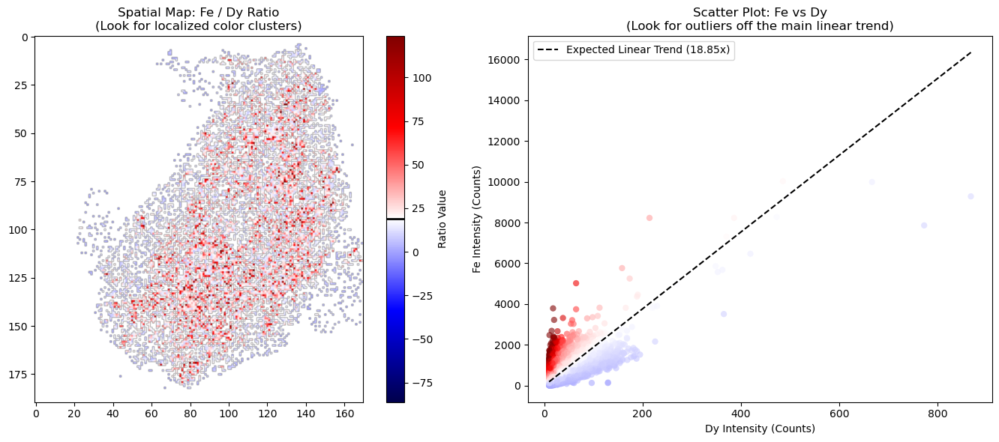

In [15]:
checkElementalRatio(Fe, Dy, "Fe", "Dy")

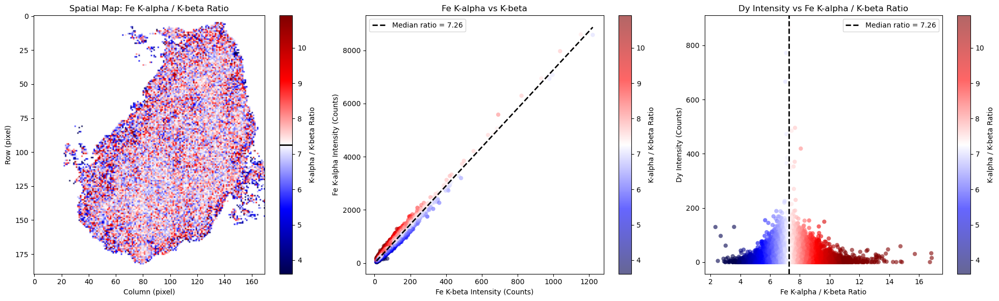


Fe K-alpha / K-beta ANALYSIS
Valid pixels: 15,255
Median Fe K-alpha / K-beta ratio: 7.2632
Dy count range: 0.00 - 867.08


In [16]:
results = checkFeRatioWithDy(counts, Dy)


Fe RATIO / Dy ANOMALY SELECTION
High Dy threshold (90th percentile): 61.768
Low Fe ratio threshold (1th percentile): 4.629
High Fe ratio threshold (99th percentile): 10.913

HIGH Fe RATIO + HIGH Dy
----------------------------------------------------------------------

LOW Fe RATIO + HIGH Dy
----------------------------------------------------------------------
Pixel (x, y)=(147, 28) | Fe ratio=2.3380 | Dy=129.437
Pixel (x, y)=(148, 28) | Fe ratio=2.6897 | Dy=96.576
Pixel (x, y)=(148, 27) | Fe ratio=3.5882 | Dy=129.862


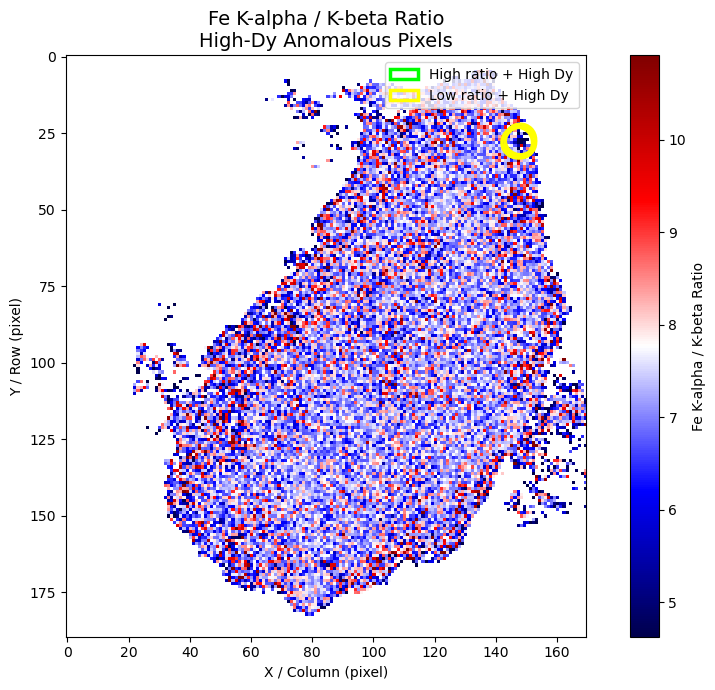

In [17]:
anomalies = findFeRatioDyAnomalies(
    results,
    Dy,
    dy_percentile=90,
    ratio_low_percentile=1,
    ratio_high_percentile=99,
    circle_radius=5,
    max_points=20
)


========== Fe K-alpha FWHM vs Dy ==========
Valid pixels: 9,823


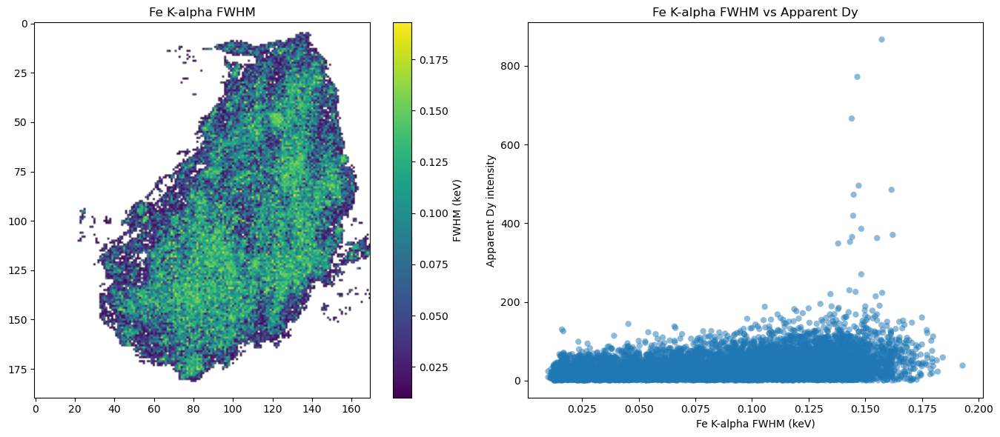

In [18]:
ka_fwhm_results = checkFeKaFWHMvsDy(
    counts,
    Dy
)


========== Fe K-alpha/K-beta FWHM RATIO ==========
Valid pixels: 14,085
Median ratio: 3.7760


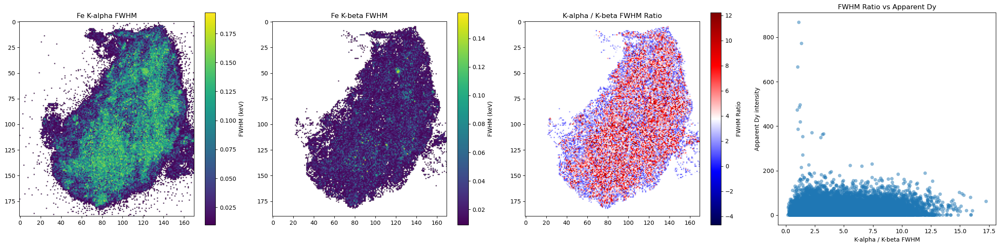

In [25]:
fwhm_ratio_results = checkFeFWHMRatioVsDy(
    counts,
    Dy
)


========== Fe K-alpha ASYMMETRY vs Dy ==========
Valid pixels: 14,111
Median asymmetry: 0.02730


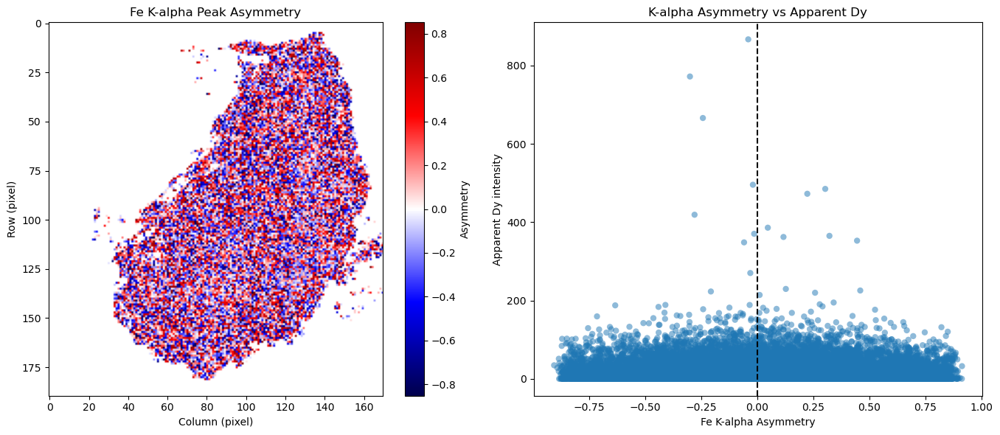

In [20]:
asymmetry_results = checkFeKaAsymmetryVsDy(
    counts,
    Dy
)

Calculating Fe K-alpha / K-beta FWHM...

Fe K-alpha / K-beta FWHM RATIO
Valid pixels:        30,764
Median FWHM ratio:   3.8036
Mean FWHM ratio:     4.4869
Minimum ratio:       0.1691
Maximum ratio:       16.2168


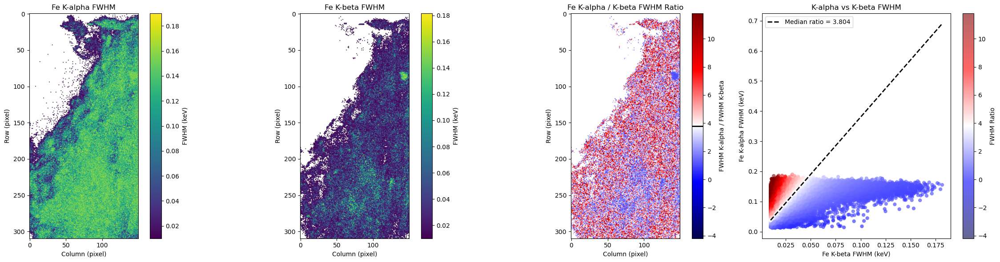

In [41]:
checkFeFWHMRatio(counts)

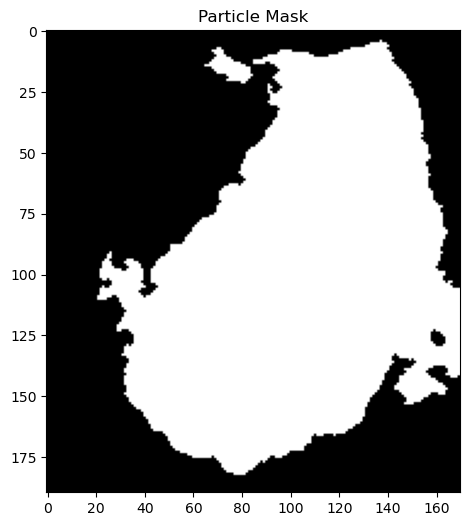

In [26]:
particle_mask = create_particle_mask(
    Fe+Dy,
    min_particle_size=20
)
plt.figure(figsize=(6, 6))

plt.imshow(
    particle_mask,
    cmap="gray"
)

plt.title("Particle Mask")

plt.show()

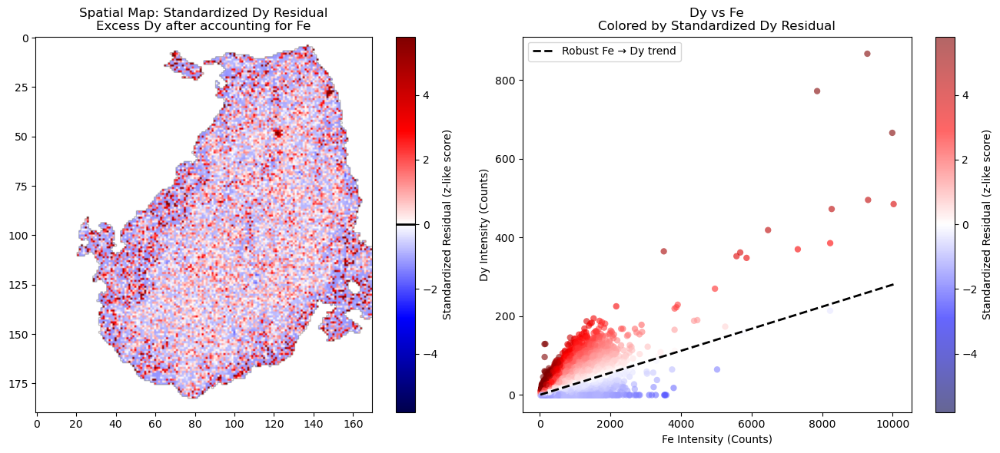

In [27]:
results = checkDyResidualStandardizedMasked(Fe, Dy, "Fe", "Dy", particle_mask=particle_mask,)


HIGHEST STANDARDIZED Dy RESIDUAL
Pixel coordinate (row, col): (28, 147)
Plot coordinate (x, y): (147, 28)
Fe intensity:             130.459
Measured Dy:              129.437
Predicted Dy from Fe:     4.131
Raw Dy residual:          125.307
Standardized residual:     35.817

LOWEST STANDARDIZED Dy RESIDUAL
Pixel coordinate (row, col): (69, 134)
Plot coordinate (x, y): (134, 69)
Fe intensity:             3581.636
Measured Dy:              0.000
Predicted Dy from Fe:     100.746
Raw Dy residual:          -100.746
Standardized residual:     -1.870


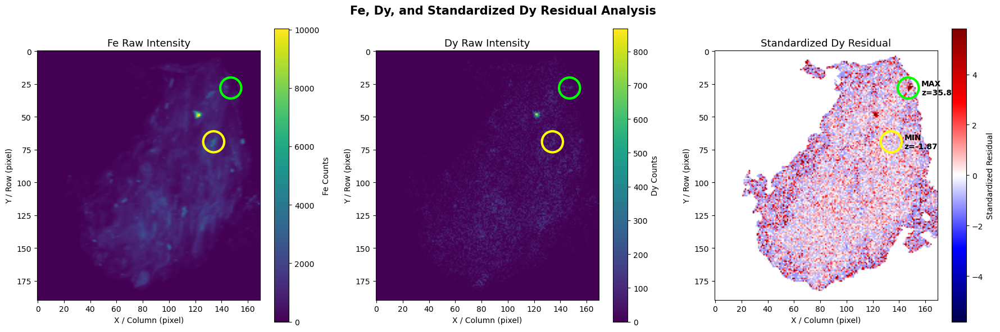

In [28]:
selected = selectResidualExtremes(
    results,
    Fe,
    Dy,
    circle_radius=8,
    custom_circle_cord=None
)
# custom_circle_cord=(78, 212)

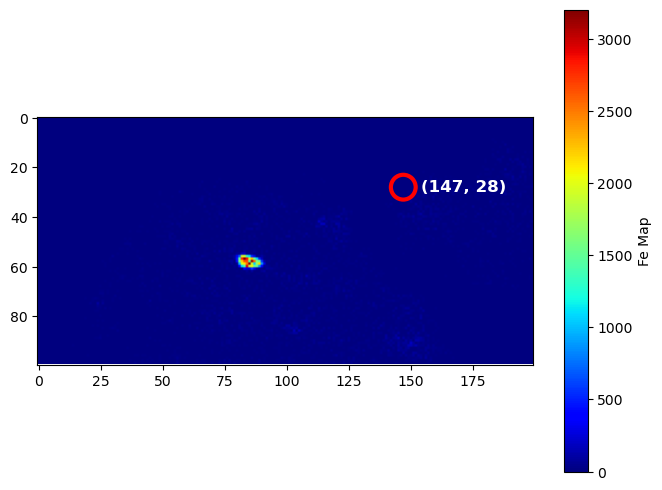

In [149]:

circle_coord = (147, 28)  # (X, Y) = (column, row)
circle_radius = 5

plt.figure(figsize=(8, 6))

plt.imshow(Dy, cmap="jet")
plt.colorbar(label="Fe Map")


circle = Circle(
    circle_coord,
    radius=circle_radius,
    fill=False,
    edgecolor="red",
    linewidth=3
)

plt.gca().add_patch(circle)


# Optional: add coordinate label
plt.text(
    circle_coord[0] + circle_radius + 2,
    circle_coord[1],
    f"({circle_coord[0]}, {circle_coord[1]})",
    color="white",
    fontsize=12,
    fontweight="bold",
    va="center"
)


# plt.title("Pixel-level Ce–Nd–P Colocalization")
# plt.axis("off")

plt.show()

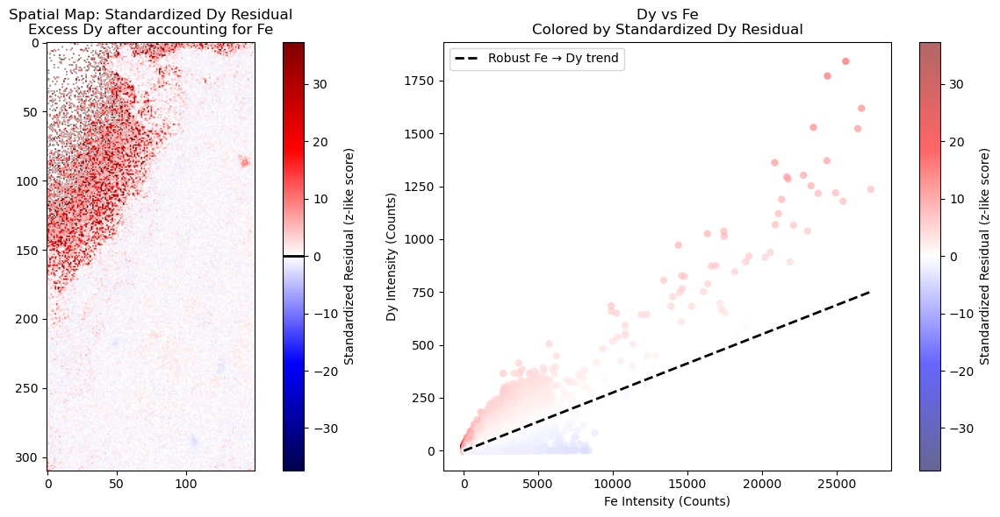


========== STANDARDIZED Dy RESIDUAL ANALYSIS ==========
Valid pixels: 43,352
Median raw residual: 1.160 counts
Median local residual sigma: 35.232 counts
Median standardized residual: 0.231
99th percentile |standardized residual|: 37.376
Pixels with standardized residual > 2: 8,877
Pixels with standardized residual > 3: 7,138


{'model': Pipeline(steps=[('standardscaler', StandardScaler()),
                 ('huberregressor', HuberRegressor())]),
 'raw_residual_map': array([[        nan,         nan,         nan, ...,  0.79117102,
         12.00067926,  0.49207419],
        [        nan,         nan,         nan, ...,  2.84995946,
          2.68542253,  0.60708919],
        [        nan,         nan,         nan, ..., -0.21012998,
         -0.31995884,  2.66249951],
        ...,
        [ 4.19556305,  0.84404333,  1.07366895, ..., -2.38745536,
         -6.89100121, 16.90005571],
        [ 1.09520446,  0.46089077,  0.8594412 , ..., 32.09366709,
          9.76571502, -2.23892481],
        [ 1.07530558,  2.22541144,  5.1806349 , ..., -8.20068856,
          8.45200574, -0.87345064]]),
 'standardized_residual_map': array([[        nan,         nan,         nan, ...,  1.20599819,
         28.26475969,  0.39777779],
        [        nan,         nan,         nan, ...,  2.9347276 ,
          2.57163623,  0.65166976],

In [14]:
checkDyResidualStandardized(Fe, Dy, "Fe", "Dy")

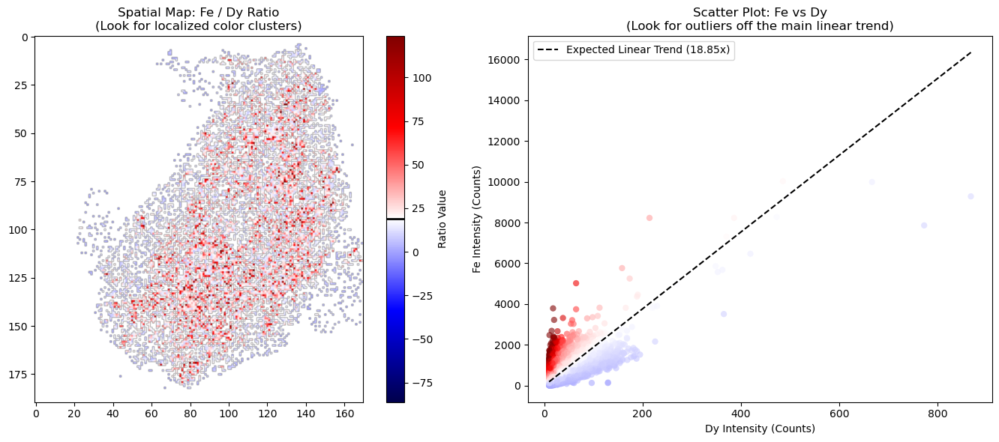

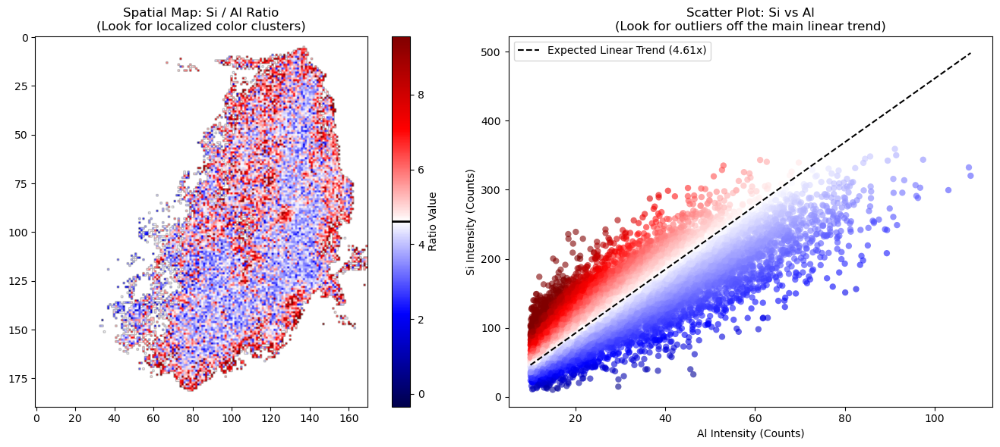

In [11]:
checkElementalRatio(Si, Al, "Si", "Al")

Map shape: (310, 150)
Initial observations: 78


/Users/Lawrence/xraylarch/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(



Next ROI:
Pixel X: 87
Pixel Y: 216
Predicted probability: 0.893665426925736
Uncertainty: 0.3082653591362124
Acquisition value: 1.0477981064938422
Next ROI pixel: X=87, Y=216


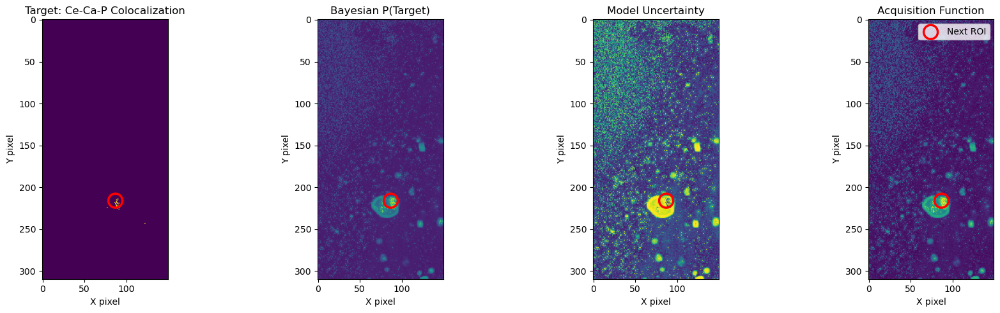

In [68]:
results = run_bayesian_roi_model(
    Ce,
    Ca,
    P,
    n_initial=100,
    colocalization_threshold=0.8,
    exploration_weight=0.5
)

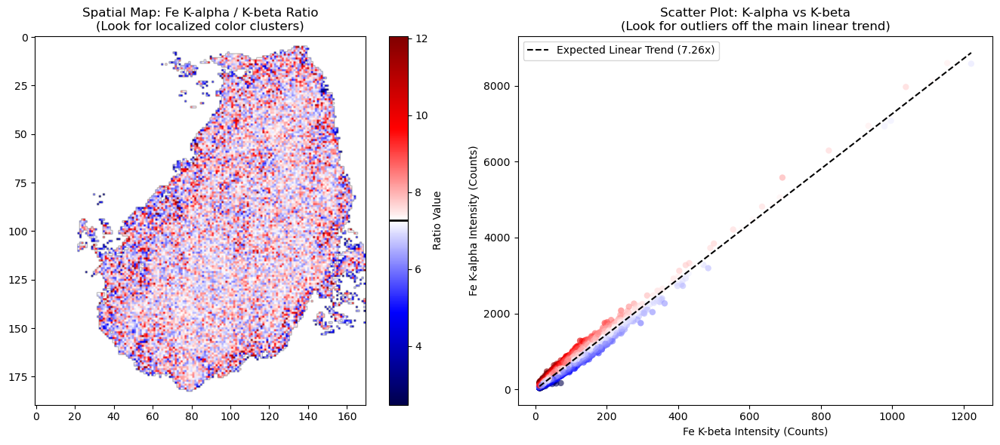

In [5]:
checkFeRatio(counts)

Calculating background-subtracted Fe peak areas...

BACKGROUND-SUBTRACTED Fe Kα / Kβ AREA RATIO
Valid pixels:       15,251
Median ratio:       6.8800
Mean ratio:         7.0869
1st percentile:     4.2121
99th percentile:    11.9020


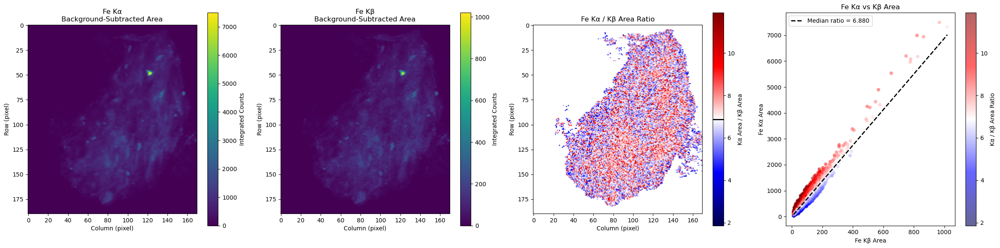

{'ka_area_map': array([[1., 0., 1., ..., 2., 1., 1.],
        [0., 2., 2., ..., 3., 3., 4.],
        [4., 0., 1., ..., 2., 2., 2.],
        ...,
        [2., 0., 5., ..., 2., 8., 4.],
        [1., 2., 2., ..., 5., 7., 3.],
        [2., 2., 4., ..., 3., 1., 3.]]),
 'kb_area_map': array([[0., 0., 0., ..., 1., 1., 0.],
        [1., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 2., 0., 1.],
        ...,
        [0., 0., 1., ..., 1., 1., 0.],
        [0., 0., 0., ..., 0., 2., 3.],
        [2., 0., 1., ..., 0., 1., 1.]]),
 'ratio_map': array([[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]),
 'valid_pixels': array([[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, Fa

In [5]:
checkFeRatioNew(counts)

Calculating Fe K-alpha / K-beta FWHM...

Fe K-alpha / K-beta FWHM RATIO
Valid pixels:        24,457
Median FWHM ratio:   2.0000
Mean FWHM ratio:     3.1777
Minimum ratio:       0.1831
Maximum ratio:       17.2500


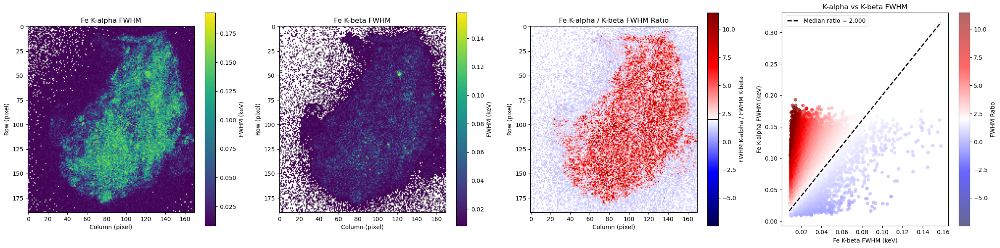

In [5]:
checkFeFWHMRatio(counts)

In [7]:
Ce_n = percentile_normalize(Ce)
Nd_n = percentile_normalize(Nd)
P_n  = percentile_normalize(P)
Ca_n = percentile_normalize(Ca)
Al_n = percentile_normalize(Al)
Si_n  = percentile_normalize(Si)
Fe_n = percentile_normalize(Fe)
S_n  = percentile_normalize(S)
Y_n = percentile_normalize(Y)
Zr_n = percentile_normalize(Zr)
La_n = percentile_normalize(La)

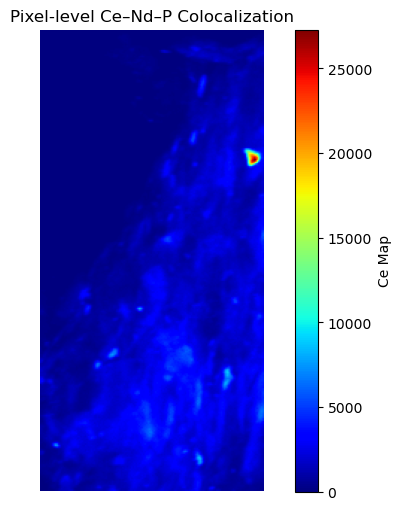

In [15]:
plt.figure(figsize=(8, 6))

plt.imshow(Fe, cmap="jet")
plt.colorbar(label="Ce Map")

plt.title("Pixel-level Ce–Nd–P Colocalization")
plt.axis("off")

plt.show()

In [11]:
# C_direct = Ce_n * Nd_n * La_n * Ca_n
C_direct1 = Ce_n * P_n
# C_direct2 = Ce_n * P_n * Ca_n
# C_direct = C_direct2 - C_direct1
C_direct = Ce_n * Ca_n * P_n
Ce_noncoloc = Ce_n * (1 - Ca_n * P_n)

Ce_present = Ce_n > 0.9
Ca_present = Ca_n > 0.5
P_present  = P_n > 0.5

Ce_noncoloc_mask = (
    Ce_present &
    ~(P_present)
)
Ce_noncoloc_map = np.where(
    Ce_noncoloc_mask,
    Ce_n,
    np.nan
)

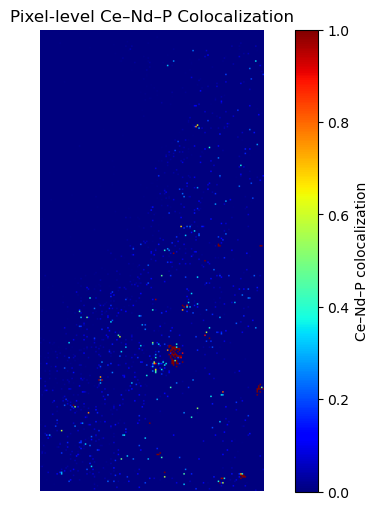

In [14]:
threshold = 0.2

C_high = np.where(C_direct > threshold, C_direct, np.nan)

plt.figure(figsize=(8, 6))

plt.imshow(C_direct1, cmap="jet")
plt.colorbar(label="Ce–Nd–P colocalization")

plt.title("Pixel-level Ce–Nd–P Colocalization")
plt.axis("off")

plt.show()

In [31]:
Ce_mask = threshold_map(Ce, 95)
Ca_mask = threshold_map(Ca, 95)
Nd_mask = threshold_map(Nd, 95)
P_mask  = threshold_map(P, 95)

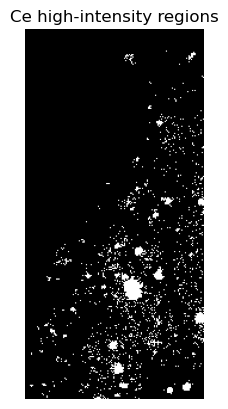

In [33]:
plt.imshow(Ce_mask, cmap="gray")
plt.title("Ce high-intensity regions")
plt.axis("off")
plt.show()

In [34]:
from scipy.ndimage import binary_dilation

def dilate_mask(mask, radius=3):

    y, x = np.ogrid[-radius:radius+1,
                    -radius:radius+1]

    footprint = x*x + y*y <= radius*radius

    return binary_dilation(mask, structure=footprint)

In [35]:
Ce_near = dilate_mask(Ce_mask, radius=1)
Nd_near = dilate_mask(Nd_mask, radius=1)
Ca_near = dilate_mask(Ca_mask, radius=1)
P_near  = dilate_mask(P_mask, radius=1)

In [36]:
C_proximity_mask = Ce_near & Ce_near & P_near

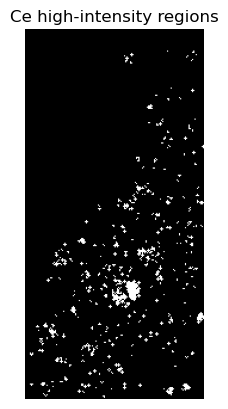

In [37]:
plt.imshow(C_proximity_mask, cmap="gray")
plt.title("Ce high-intensity regions")
plt.axis("off")
plt.show()

In [38]:
def distance_weighted_presence(
    intensity,
    mask,
    sigma=3
):
    """
    Calculates proximity-weighted elemental presence.

    sigma is in pixels.
    """

    distance = distance_transform_edt(~mask)

    weight = np.exp(
        -(distance**2) / (2 * sigma**2)
    )

    return intensity * weight

In [39]:
Ce_prox = distance_weighted_presence(
    Ce_n,
    Ce_mask,
    sigma=3
)

Nd_prox = distance_weighted_presence(
    Nd_n,
    Nd_mask,
    sigma=3
)

Ca_prox = distance_weighted_presence(
    Ca_n,
    Ca_mask,
    sigma=3
)

P_prox = distance_weighted_presence(
    P_n,
    P_mask,
    sigma=3
)

In [40]:
C_proximity = (
    Ce_prox *
    Ca_prox *
    P_prox
)

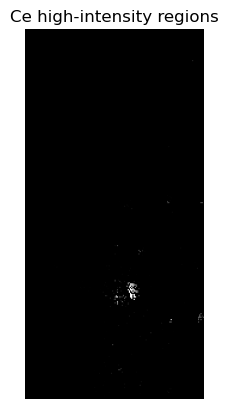

In [41]:
plt.imshow(C_proximity, cmap="gray")
plt.title("Ce high-intensity regions")
plt.axis("off")
plt.show()

In [42]:
alpha = 0.7

C_total = (
    alpha * C_direct +
    (1 - alpha) * C_proximity
)

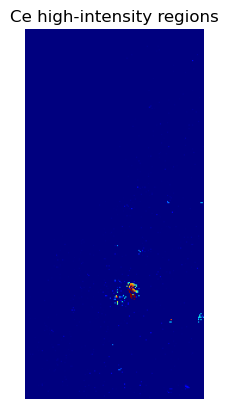

In [43]:
plt.imshow(C_total, cmap="jet")
plt.title("Ce high-intensity regions")
plt.axis("off")
plt.show()

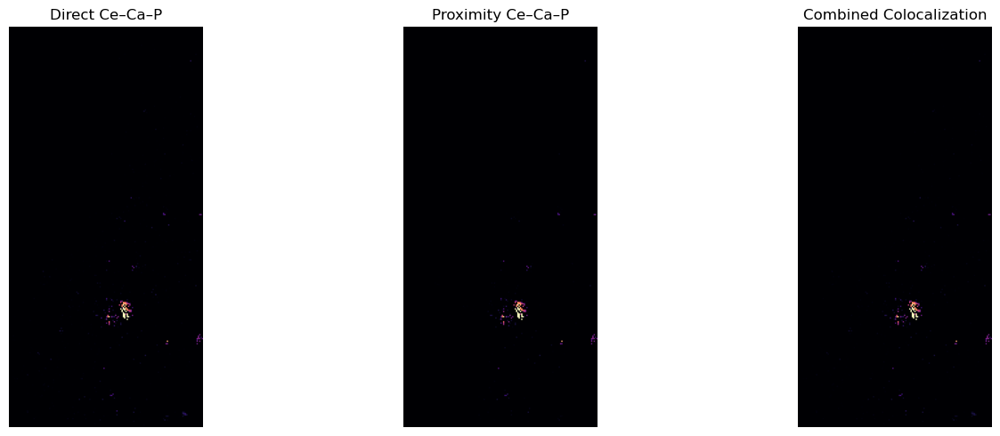

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(C_direct, cmap="magma")
axes[0].set_title("Direct Ce–Ca–P")
axes[0].axis("off")

axes[1].imshow(C_proximity, cmap="magma")
axes[1].set_title("Proximity Ce–Ca–P")
axes[1].axis("off")

axes[2].imshow(C_total, cmap="magma")
axes[2].set_title("Combined Colocalization")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [45]:
C_min = np.minimum.reduce([
    Ce_n,
    Ca_n,
    P_n
])

C_geo = (
    Ce_n *
    Ca_n *
    P_n
) ** (1/3)

threshold = 0.2

valid = (
    (Ce_n > threshold) &
    (Ca_n > threshold) &
    (P_n > threshold)
)

C_geo_thresholded = np.where(
    valid,
    C_geo,
    0
)

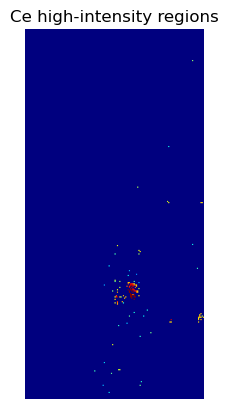

In [46]:
plt.imshow(C_geo_thresholded, cmap="jet")
plt.title("Ce high-intensity regions")
plt.axis("off")
plt.show()

In [47]:
def calculate_roi_scores(
    C_map,
    roi_height=25,
    roi_width=25
):

    h, w = C_map.shape

    scores = []

    for y in range(0, h - roi_height + 1, roi_height):

        for x in range(0, w - roi_width + 1, roi_width):

            roi = C_map[
                y:y+roi_height,
                x:x+roi_width
            ]

            score = np.nanmean(roi)

            scores.append({
                "x": x,
                "y": y,
                "width": roi_width,
                "height": roi_height,
                "colocalization": score
            })

    return scores

def roi_statistics(roi):

    return {
        "mean": np.nanmean(roi),
        "median": np.nanmedian(roi),
        "max": np.nanmax(roi),
        "p90": np.nanpercentile(roi, 90),
        "p95": np.nanpercentile(roi, 95),
        "fraction_high": np.mean(roi > 0.5)
    }

In [48]:
roi_scores = calculate_roi_scores(
    C_total,
    roi_height=25,
    roi_width=25
)

In [49]:
import pandas as pd

roi_df = pd.DataFrame(roi_scores)

print(
    roi_df.sort_values(
        "colocalization",
        ascending=False
    ).head(10)
)

      x    y  width  height  colocalization
51   75  200     25      25        0.071285
57   75  225     25      25        0.009567
59  125  225     25      25        0.006112
58  100  225     25      25        0.002553
45   75  175     25      25        0.002204
69   75  275     25      25        0.001675
50   50  200     25      25        0.001475
34  100  125     25      25        0.001465
35  125  125     25      25        0.001011
56   50  225     25      25        0.000838


In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import (
    binary_dilation,
    binary_erosion,
    distance_transform_edt,
    gaussian_filter
)


# ============================================================
# 1. LOAD ELEMENT MAPS
# ============================================================

# Use your existing PyXRF function
Ce = get_element_map("Ce_L")
Nd = get_element_map("Ca_L")
P  = get_element_map("P_K")


# Convert to floating point
Ce = np.asarray(Ce, dtype=float)
Nd = np.asarray(Nd, dtype=float)
P  = np.asarray(P, dtype=float)


# ============================================================
# 2. CHECK MAPS
# ============================================================

if not (Ce.shape == Nd.shape == P.shape):
    raise ValueError(
        f"Element maps must have identical dimensions.\n"
        f"Ce: {Ce.shape}\n"
        f"Nd: {Nd.shape}\n"
        f"P:  {P.shape}"
    )

print("Map shape:", Ce.shape)


# ============================================================
# 3. REMOVE INVALID VALUES
# ============================================================

Ce = np.nan_to_num(Ce, nan=0.0, posinf=0.0, neginf=0.0)
Nd = np.nan_to_num(Nd, nan=0.0, posinf=0.0, neginf=0.0)
P  = np.nan_to_num(P,  nan=0.0, posinf=0.0, neginf=0.0)


# ============================================================
# 4. PERCENTILE NORMALIZATION
# ============================================================

def percentile_normalize(img, low=1, high=99):
    """
    Normalize an XRF elemental map using percentile limits.

    Output is constrained to [0, 1].
    """

    img = np.asarray(img, dtype=float)

    p_low = np.nanpercentile(img, low)
    p_high = np.nanpercentile(img, high)

    if p_high <= p_low:
        return np.zeros_like(img)

    norm = (img - p_low) / (p_high - p_low)

    return np.clip(norm, 0, 1)


Ce_n = percentile_normalize(Ce)
Nd_n = percentile_normalize(Nd)
P_n  = percentile_normalize(P)


# ============================================================
# 5. CREATE ELEMENT PRESENCE MASKS
# ============================================================

def create_presence_mask(
    img,
    percentile=75
):
    """
    Creates a binary mask representing relatively
    high-intensity regions of an elemental map.
    """

    threshold = np.nanpercentile(img, percentile)

    mask = img >= threshold

    return mask, threshold


# You can change this threshold.
#
# 75 means the top 25% of pixels are considered
# relatively high-intensity.
#
# Later, I recommend replacing this with an SNR-based
# threshold.

Ce_mask, Ce_threshold = create_presence_mask(
    Ce_n,
    percentile=75
)

Nd_mask, Nd_threshold = create_presence_mask(
    Nd_n,
    percentile=75
)

P_mask, P_threshold = create_presence_mask(
    P_n,
    percentile=75
)


print("Ce threshold:", Ce_threshold)
print("Nd threshold:", Nd_threshold)
print("P threshold:", P_threshold)


# ============================================================
# 6. DIRECT PIXEL-LEVEL COLocalization
# ============================================================

# Geometric mean is used rather than simply Ce * Nd * P.
#
# This gives:
#
# C = (Ce * Nd * P)^(1/3)
#
# It is less dominated by very large values.

C_direct = (
    Ce_n *
    Nd_n *
    P_n
) ** (1 / 3)


# ============================================================
# 7. THRESHOLDED DIRECT COLOCALIZATION
# ============================================================

# Only consider pixels where all three elements have
# meaningful signal.

valid_direct = (
    Ce_mask &
    Nd_mask &
    P_mask
)

C_direct_thresholded = np.where(
    valid_direct,
    C_direct,
    0
)


# ============================================================
# 8. DISTANCE-WEIGHTED PROXIMITY
# ============================================================

def distance_weighted_presence(
    intensity,
    presence_mask,
    sigma_pixels=3
):
    """
    Calculate distance-weighted elemental presence.

    Pixels close to the elemental region receive high values.

    Weight:
        exp(-d^2 / (2*sigma^2))

    sigma_pixels controls the spatial scale of association.
    """

    # Distance from every pixel to the nearest True pixel
    distance = distance_transform_edt(
        ~presence_mask
    )

    weight = np.exp(
        -(distance ** 2) /
        (2 * sigma_pixels ** 2)
    )

    return intensity * weight


# Spatial scale of proximity.
#
# Example:
# sigma = 3 pixels
#
# If your pixel size is 0.5 um:
# sigma = 3 pixels = 1.5 um

sigma_pixels = 3


Ce_prox = distance_weighted_presence(
    Ce_n,
    Ce_mask,
    sigma_pixels
)

Nd_prox = distance_weighted_presence(
    Nd_n,
    Nd_mask,
    sigma_pixels
)

P_prox = distance_weighted_presence(
    P_n,
    P_mask,
    sigma_pixels
)


# ============================================================
# 9. PROXIMITY-BASED Ce-Nd-P COLOCALIZATION
# ============================================================

C_proximity = (
    Ce_prox *
    Nd_prox *
    P_prox
) ** (1 / 3)


# ============================================================
# 10. COMBINE DIRECT + PROXIMITY
# ============================================================

alpha = 0.7

C_total = (
    alpha * C_direct_thresholded +
    (1 - alpha) * C_proximity
)


# ============================================================
# 11. ROI STATISTICS
# ============================================================

def roi_statistics(roi):
    """
    Calculate statistical descriptors for a colocalization ROI.
    """

    roi = np.asarray(roi, dtype=float)

    roi = roi[np.isfinite(roi)]

    if roi.size == 0:
        return {
            "mean": np.nan,
            "median": np.nan,
            "max": np.nan,
            "p90": np.nan,
            "p95": np.nan,
            "fraction_high": np.nan
        }

    p95 = np.percentile(roi, 95)

    return {
        "mean": np.mean(roi),
        "median": np.median(roi),
        "max": np.max(roi),
        "p90": np.percentile(roi, 90),
        "p95": p95,
        "fraction_high": np.mean(roi >= 0.5)
    }


# ============================================================
# 12. ROI SCORE
# ============================================================

def calculate_roi_score(
    stats,
    w1=0.5,
    w2=0.3,
    w3=0.2
):
    """
    Calculate:

        C_ROI = w1*P95 + w2*Cmean + w3*fhigh

    where:
        P95  = 95th percentile colocalization
        Cmean = mean colocalization
        fhigh = fraction of highly colocalized pixels

    The weights should sum to 1.
    """

    if not np.isclose(
        w1 + w2 + w3,
        1.0
    ):
        raise ValueError(
            "ROI weights must sum to 1."
        )

    return (
        w1 * stats["p95"] +
        w2 * stats["mean"] +
        w3 * stats["fraction_high"]
    )


# ============================================================
# 13. CREATE ROIS
# ============================================================

def generate_rois(
    image_shape,
    roi_height=25,
    roi_width=25,
    step_y=None,
    step_x=None
):
    """
    Generate rectangular ROIs.

    step_y / step_x control overlap between ROIs.

    If step = ROI size:
        no overlap.

    If step < ROI size:
        overlapping ROIs.
    """

    h, w = image_shape

    if step_y is None:
        step_y = roi_height

    if step_x is None:
        step_x = roi_width

    rois = []

    roi_id = 0

    for y in range(
        0,
        h - roi_height + 1,
        step_y
    ):

        for x in range(
            0,
            w - roi_width + 1,
            step_x
        ):

            rois.append({
                "roi_id": roi_id,
                "x": x,
                "y": y,
                "width": roi_width,
                "height": roi_height
            })

            roi_id += 1

    return rois


# ============================================================
# 14. EXTRACT ROI
# ============================================================

def extract_roi(
    image,
    roi
):
    """
    Extract image region from ROI dictionary.
    """

    x = roi["x"]
    y = roi["y"]

    w = roi["width"]
    h = roi["height"]

    return image[
        y:y+h,
        x:x+w
    ]


# ============================================================
# 15. INTERFACE / BOUNDARY DETECTION
# ============================================================

def get_boundary(
    mask,
    erosion_iterations=1
):
    """
    Extract the boundary of a binary elemental region.

    Boundary = mask - eroded mask.
    """

    eroded = binary_erosion(
        mask,
        iterations=erosion_iterations
    )

    boundary = mask & ~eroded

    return boundary


# ============================================================
# 16. CREATE INTERFACE BAND
# ============================================================

def create_interface_band(
    boundary,
    radius_pixels=3
):
    """
    Create a band surrounding an elemental boundary.

    The band includes pixels within radius_pixels
    of the boundary.
    """

    if radius_pixels < 1:
        return boundary.copy()

    y, x = np.ogrid[
        -radius_pixels:radius_pixels + 1,
        -radius_pixels:radius_pixels + 1
    ]

    footprint = (
        x*x + y*y <=
        radius_pixels*radius_pixels
    )

    dilated = binary_dilation(
        boundary,
        structure=footprint
    )

    band = dilated & ~boundary

    return band


# ============================================================
# 17. INTERFACE ASSOCIATION
# ============================================================

def interface_association(
    host_mask,
    associated_intensity,
    interface_radius=3
):
    """
    Determine whether an associated element is concentrated
    near the boundary of a host element.

    Example:

        host = Ce
        associated = Nd

    asks:

        How much Nd occurs near the boundary
        of Ce-rich regions?

    Returns:
        interface_score
        interface_mean
        roi_mean
        enrichment_ratio
        boundary
        interface_band
    """

    boundary = get_boundary(
        host_mask
    )

    interface_band = create_interface_band(
        boundary,
        radius_pixels=interface_radius
    )

    # Intensity near host boundary
    interface_values = associated_intensity[
        interface_band
    ]

    # Mean associated-element intensity
    # across entire ROI/image
    overall_mean = np.mean(
        associated_intensity
    )

    if interface_values.size == 0:
        return {
            "score": 0.0,
            "interface_mean": 0.0,
            "overall_mean": overall_mean,
            "enrichment_ratio": 0.0,
            "boundary": boundary,
            "interface_band": interface_band
        }

    interface_mean = np.mean(
        interface_values
    )

    # Avoid division by zero
    if overall_mean > 1e-12:

        enrichment_ratio = (
            interface_mean /
            overall_mean
        )

    else:
        enrichment_ratio = 0.0

    # Convert enrichment into a bounded 0-1 score.
    #
    # If interface = overall:
    # score = 0.5
    #
    # If interface >> overall:
    # score approaches 1.
    #
    # If interface << overall:
    # score approaches 0.

    score = (
        interface_mean /
        (
            interface_mean +
            overall_mean +
            1e-12
        )
    )

    return {
        "score": score,
        "interface_mean": interface_mean,
        "overall_mean": overall_mean,
        "enrichment_ratio": enrichment_ratio,
        "boundary": boundary,
        "interface_band": interface_band
    }


# ============================================================
# 18. EDGE / PROXIMITY ASSOCIATION BETWEEN TWO ELEMENTS
# ============================================================

def edge_association(
    mask_A,
    intensity_B,
    sigma_pixels=3
):
    """
    Calculate how strongly element B occurs close to
    element A.

    This does NOT require A and B to occupy the same pixels.

    Example:

        mask_A = Ce mask
        intensity_B = Nd map

    asks:

        How strongly does Nd occur near Ce?
    """

    distance = distance_transform_edt(
        ~mask_A
    )

    weights = np.exp(
        -(distance ** 2) /
        (2 * sigma_pixels ** 2)
    )

    weighted_B = (
        intensity_B *
        weights
    )

    # Evaluate around A-bearing pixels
    A_values = weighted_B[
        mask_A
    ]

    if A_values.size == 0:
        return {
            "score": 0.0,
            "mean_weighted_B": 0.0,
            "mean_distance": np.nan
        }

    score = np.mean(
        A_values
    )

    distances_at_A = distance[
        mask_A
    ]

    return {
        "score": score,
        "mean_weighted_B": score,
        "mean_distance": np.mean(
            distances_at_A
        )
    }


# ============================================================
# 19. TRIPLE-ELEMENT INTERFACE ASSOCIATION
# ============================================================

def triple_interface_association(
    host_mask,
    intensity_B,
    intensity_C,
    interface_radius=3
):
    """
    Determine whether BOTH B and C occur near the boundary
    of host element A.

    Example:

        host_mask = Ce
        intensity_B = Nd
        intensity_C = P

    asks:

        Do Nd and P both occur near Ce boundaries?
    """

    boundary = get_boundary(
        host_mask
    )

    band = create_interface_band(
        boundary,
        radius_pixels=interface_radius
    )

    B_values = intensity_B[
        band
    ]

    C_values = intensity_C[
        band
    ]

    if B_values.size == 0:
        return {
            "score": 0.0,
            "B_mean": 0.0,
            "C_mean": 0.0,
            "BC_geometric_mean": 0.0
        }

    B_mean = np.mean(B_values)
    C_mean = np.mean(C_values)

    BC_score = np.sqrt(
        B_mean * C_mean
    )

    return {
        "score": BC_score,
        "B_mean": B_mean,
        "C_mean": C_mean,
        "BC_geometric_mean": BC_score
    }


# ============================================================
# 20. ANALYZE A SINGLE ROI
# ============================================================

def analyze_roi(
    roi,
    Ce_n,
    Nd_n,
    P_n,
    Ce_mask,
    Nd_mask,
    P_mask,
    C_total,
    w1=0.5,
    w2=0.3,
    w3=0.2,
    interface_radius=3,
    sigma_pixels=3
):
    """
    Complete analysis of one ROI.
    """

    # --------------------------------------------------------
    # Extract ROI maps
    # --------------------------------------------------------

    Ce_roi = extract_roi(
        Ce_n,
        roi
    )

    Nd_roi = extract_roi(
        Nd_n,
        roi
    )

    P_roi = extract_roi(
        P_n,
        roi
    )

    Ce_mask_roi = extract_roi(
        Ce_mask,
        roi
    )

    Nd_mask_roi = extract_roi(
        Nd_mask,
        roi
    )

    P_mask_roi = extract_roi(
        P_mask,
        roi
    )

    C_roi_map = extract_roi(
        C_total,
        roi
    )


    # --------------------------------------------------------
    # ROI colocalization statistics
    # --------------------------------------------------------

    stats = roi_statistics(
        C_roi_map
    )


    # --------------------------------------------------------
    # ROI score
    # --------------------------------------------------------

    C_roi_score = calculate_roi_score(
        stats,
        w1=w1,
        w2=w2,
        w3=w3
    )


    # --------------------------------------------------------
    # Edge association
    # --------------------------------------------------------

    Ce_Nd_edge = edge_association(
        Ce_mask_roi,
        Nd_roi,
        sigma_pixels=sigma_pixels
    )

    Ce_P_edge = edge_association(
        Ce_mask_roi,
        P_roi,
        sigma_pixels=sigma_pixels
    )

    Nd_P_edge = edge_association(
        Nd_mask_roi,
        P_roi,
        sigma_pixels=sigma_pixels
    )


    # --------------------------------------------------------
    # Interface association
    # --------------------------------------------------------

    Ce_Nd_interface = interface_association(
        Ce_mask_roi,
        Nd_roi,
        interface_radius=interface_radius
    )

    Ce_P_interface = interface_association(
        Ce_mask_roi,
        P_roi,
        interface_radius=interface_radius
    )

    Nd_P_interface = interface_association(
        Nd_mask_roi,
        P_roi,
        interface_radius=interface_radius
    )


    # --------------------------------------------------------
    # Triple interface association
    #
    # Ce boundary with both Nd and P
    # --------------------------------------------------------

    Ce_NdP_interface = triple_interface_association(
        Ce_mask_roi,
        Nd_roi,
        P_roi,
        interface_radius=interface_radius
    )


    # --------------------------------------------------------
    # Triple direct intensity
    # --------------------------------------------------------

    CeNdP_direct = (
        Ce_roi *
        Nd_roi *
        P_roi
    ) ** (1 / 3)

    direct_mean = np.mean(
        CeNdP_direct
    )


    # --------------------------------------------------------
    # Return everything as a dictionary
    # --------------------------------------------------------

    result = {

        # ROI coordinates
        "roi_id":
            roi["roi_id"],

        "x":
            roi["x"],

        "y":
            roi["y"],

        "width":
            roi["width"],

        "height":
            roi["height"],


        # Main colocalization metrics
        "C_mean":
            stats["mean"],

        "C_median":
            stats["median"],

        "C_max":
            stats["max"],

        "C_P90":
            stats["p90"],

        "C_P95":
            stats["p95"],

        "fraction_high":
            stats["fraction_high"],

        "C_ROI":
            C_roi_score,


        # Direct Ce-Nd-P
        "CeNdP_direct_mean":
            direct_mean,


        # Edge association
        "Ce_Nd_edge":
            Ce_Nd_edge["score"],

        "Ce_P_edge":
            Ce_P_edge["score"],

        "Nd_P_edge":
            Nd_P_edge["score"],


        # Mean distances
        "Ce_Nd_mean_distance":
            Ce_Nd_edge["mean_distance"],

        # Interface association
        "Ce_Nd_interface":
            Ce_Nd_interface["score"],

        "Ce_P_interface":
            Ce_P_interface["score"],

        "Nd_P_interface":
            Nd_P_interface["score"],


        # Interface enrichment
        "Ce_Nd_enrichment":
            Ce_Nd_interface["enrichment_ratio"],

        "Ce_P_enrichment":
            Ce_P_interface["enrichment_ratio"],

        "Nd_P_enrichment":
            Nd_P_interface["enrichment_ratio"],


        # Triple interface
        "Ce_NdP_interface":
            Ce_NdP_interface["score"]
    }

    return result


# ============================================================
# 21. GENERATE ROIS
# ============================================================

roi_height = 25
roi_width = 25

# Set step smaller than ROI size if you want overlapping ROIs.
#
# Example:
#
# ROI = 25 x 25 pixels
# step = 12 pixels
#
# gives approximately 50% overlap.

step_y = 12
step_x = 12


rois = generate_rois(
    C_total.shape,
    roi_height=roi_height,
    roi_width=roi_width,
    step_y=step_y,
    step_x=step_x
)


print(
    "Number of candidate ROIs:",
    len(rois)
)


# ============================================================
# 22. ANALYZE ALL ROIS
# ============================================================

results = []

for roi in rois:

    result = analyze_roi(
        roi,

        Ce_n,
        Nd_n,
        P_n,

        Ce_mask,
        Nd_mask,
        P_mask,

        C_total,

        # ROI score weights
        w1=0.5,
        w2=0.3,
        w3=0.2,

        # Spatial parameters
        interface_radius=3,
        sigma_pixels=3
    )

    results.append(result)


# Convert to DataFrame
roi_df = pd.DataFrame(results)


# ============================================================
# 23. SORT BY ROI SCORE
# ============================================================

roi_df = roi_df.sort_values(
    "C_ROI",
    ascending=False
).reset_index(drop=True)


print("\nTop 10 ROIs:")
print(
    roi_df[
        [
            "roi_id",
            "x",
            "y",
            "C_ROI",
            "C_P95",
            "C_mean",
            "fraction_high",
            "Ce_Nd_edge",
            "Ce_P_edge",
            "Ce_Nd_interface",
            "Ce_NdP_interface"
        ]
    ].head(10)
)


# ============================================================
# 24. SAVE ROI RESULTS
# ============================================================

roi_df.to_csv(
    "Ce_Nd_P_ROI_analysis.csv",
    index=False
)

print(
    "\nSaved:"
    " Ce_Nd_P_ROI_analysis.csv"
)


# ============================================================
# 25. VISUALIZE DIRECT COLOCALIZATION
# ============================================================

plt.figure(figsize=(8, 6))

plt.imshow(
    C_direct_thresholded,
    cmap="magma"
)

plt.colorbar(
    label="Direct Ce-Nd-P colocalization"
)

plt.title(
    "Direct Pixel-Level Ce-Nd-P Colocalization"
)

plt.axis("off")

plt.tight_layout()

plt.show()


# ============================================================
# 26. VISUALIZE PROXIMITY COLOCALIZATION
# ============================================================

plt.figure(figsize=(8, 6))

plt.imshow(
    C_proximity,
    cmap="magma"
)

plt.colorbar(
    label="Proximity Ce-Nd-P"
)

plt.title(
    "Distance-Weighted Ce-Nd-P Proximity"
)

plt.axis("off")

plt.tight_layout()

plt.show()


# ============================================================
# 27. VISUALIZE COMBINED COLOCALIZATION
# ============================================================

plt.figure(figsize=(8, 6))

plt.imshow(
    C_total,
    cmap="magma"
)

plt.colorbar(
    label="Combined colocalization"
)

plt.title(
    "Combined Ce-Nd-P Colocalization"
)

plt.axis("off")

plt.tight_layout()

plt.show()


# ============================================================
# 28. SHOW TOP ROIs ON COLOCALIZATION MAP
# ============================================================

top_n = 10

top_rois = roi_df.head(top_n)


plt.figure(figsize=(10, 8))

plt.imshow(
    C_total,
    cmap="magma"
)

for rank, (_, row) in enumerate(
    top_rois.iterrows(),
    start=1
):

    x = row["x"]
    y = row["y"]
    w = row["width"]
    h = row["height"]

    rect = plt.Rectangle(
        (x, y),
        w,
        h,
        fill=False,
        linewidth=2
    )

    plt.gca().add_patch(rect)

    plt.text(
        x,
        y,
        str(rank),
        fontsize=12,
        fontweight="bold",
        color="white",
        bbox=dict(
            facecolor="black",
            alpha=0.6
        )
    )


plt.colorbar(
    label="Combined colocalization"
)

plt.title(
    f"Top {top_n} Candidate ROIs"
)

plt.axis("off")

plt.tight_layout()

plt.show()

TypeError: get_element_map() missing 2 required positional arguments: 'xrf_names' and 'xrf_fit'